# Notebook 01 — Carga y Limpieza del Dataset
### *Student Performance Factors*

---

## Objetivo del notebook

Este notebook realiza la **primera etapa del pipeline de datos**:

1. **Carga** del dataset crudo desde `data/raw/`.
2. **Diagnóstico** inicial (tipos, nulos, duplicados, rangos).
3. **Limpieza** y tratamiento de valores atípicos/faltantes.
4. **Feature engineering** básico (variable objetivo binaria `Approved`).
5. **Exportación** del dataset limpio a `data/processed/`.


> **Nota metodológica:** las decisiones tomadas aquí (imputación, umbral de aprobación, filtros) quedan documentadas y son **revisables** en etapas posteriores de modelamiento.

---

## Estructura del notebook

| # | Sección | Descripción |
|---|---------|-------------|
| 1 | Configuración inicial | Imports, rutas, reproducibilidad |
| 2 | Carga y diagnóstico | Exploración del dataset crudo |
| 3 | Limpieza del target | Filtrado de `Exam_Score` y `Attendance` |
| 4 | Valores faltantes | Imputación mediana/moda, categóricas |
| 5 | Feature engineering | Variable `Approved` |
| 6 | Exportación | Guardado del dataset procesado |

## 1️ Configuración inicial

### 1.1 Imports y parámetros globales

Cargamos las librerías estándar del stack de análisis de datos y definimos una **semilla aleatoria** para garantizar que todos los resultados sean reproducibles.

In [127]:
# 01_carga_y_limpieza.ipynb
# Carga y limpieza inicial del dataset "Student Performance Factors"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configuración visual
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style("whitegrid")

# Reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Parámetros del pipeline 
# Umbral de aprobación sobre Exam_Score (escala 0–100).
# NOTA: 59.5 genera un desbalance extremo (~99:1). Se adopta 65
# (percentil 25) para obtener clases ~75/25, tratables en clasificación.
UMBRAL_APROBACION = 65

# Rango válido de Exam_Score y Attendance (porcentaje)
SCORE_MIN, SCORE_MAX = 0, 100

### 1.2 Definición de rutas

Usamos `pathlib.Path` para construir rutas **relativas a la raíz del repositorio**, lo que hace el notebook portable entre máquinas.

- `RAW_PATH` → dataset original (no se modifica nunca).
- `PROCESSED_PATH` → dataset limpio, listo para modelar.

In [128]:
# Rutas relativas a la raíz del repositorio
RAW_PATH       = Path("../data/raw/StudentPerformanceFactors.csv")
PROCESSED_PATH = Path("../data/processed/student_performance_clean.csv")

# Crear la carpeta processed si no existe
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)

## 2️ Carga y diagnóstico inicial

### 2.1 Lectura del CSV

El archivo original usa `"NA"` como marcador de valor faltante, además de strings vacíos. Se los indica explícitamente a `pandas` para que los convierta en `NaN` desde el inicio.

In [129]:
# Carga del CSV. Ojo: el archivo usa "NA" como valor faltante
df = pd.read_csv(RAW_PATH, na_values=["NA", "", " "])

print(f"Shape: {df.shape}")
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head()

Shape: (6607, 20)
Filas: 6607 | Columnas: 20


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23.0,84.0,Low,High,No,7,73,Low,Yes,0.0,Low,Medium,Public,Positive,3.0,No,High School,Near,Male,67.0
1,19.0,64.0,Low,Medium,No,8,59,Low,Yes,NaN,Medium,Medium,Public,Negative,4.0,No,College,Moderate,Female,61.0
2,24.0,98.0,Medium,Medium,Yes,7,91,Medium,Yes,2.0,Medium,Medium,Public,Neutral,4.0,No,Postgraduate,Near,Male,74.0
3,29.0,89.0,Low,Medium,Yes,8,98,Medium,Yes,1.0,Medium,Medium,Public,Negative,4.0,No,High School,Moderate,Male,71.0
4,19.0,92.0,Medium,Medium,Yes,6,65,Medium,Yes,3.0,Medium,High,Public,Neutral,4.0,No,College,Near,Female,70.0


### 2.2 Estructura del dataset

Revisamos:

- **Tipos de datos** por columna (`df.info()`).
- **Estadísticas descriptivas** de variables numéricas.
- **Resumen de variables categóricas** (cardinalidad, moda, frecuencia).

In [130]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Hours_Studied               6605 non-null   float64
 1   Attendance                  6605 non-null   float64
 2   Parental_Involvement        6606 non-null   object 
 3   Access_to_Resources         6605 non-null   object 
 4   Extracurricular_Activities  6605 non-null   object 
 5   Sleep_Hours                 6607 non-null   int64  
 6   Previous_Scores             6607 non-null   int64  
 7   Motivation_Level            6606 non-null   object 
 8   Internet_Access             6606 non-null   object 
 9   Tutoring_Sessions           6606 non-null   float64
 10  Family_Income               6606 non-null   object 
 11  Teacher_Quality             6528 non-null   object 
 12  School_Type                 6605 non-null   object 
 13  Peer_Influence              6606 

In [131]:
# Resumen estadístico de variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6605.0,19.973808,5.995209,0.0,16.0,20.0,24.0,44.0
Attendance,6605.0,79.948978,11.736506,-91.0,70.0,80.0,90.0,100.0
Sleep_Hours,6607.0,7.029060,1.468120,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6606.0,1.493642,1.230648,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6604.0,2.967293,1.031015,0.0,2.0,3.0,4.0,6.0
Exam_Score,6605.0,67.215291,4.217186,-65.0,65.0,67.0,69.0,101.0


In [132]:
# Resumen de variables categóricas
df.describe(include="object").T

,count,unique,top,freq
Parental_Involvement,6606,3,Medium,3362
Access_to_Resources,6605,3,Medium,3318
Extracurricular_Activities,6605,2,Yes,3937
Motivation_Level,6606,3,Medium,3351
Internet_Access,6606,2,Yes,6107
Family_Income,6606,3,Low,2672
Teacher_Quality,6528,3,Medium,3924
School_Type,6605,2,Public,4597
Peer_Influence,6606,3,Positive,2638
Learning_Disabilities,6607,2,No,5912


### 2.3 Valores faltantes

Antes de imputar, **cuantificamos** cuántos nulos hay y en qué columnas. Este diagnóstico guía la estrategia de imputación.

In [133]:
# Conteo y porcentaje de nulos por columna
missing = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().sum() / len(df) * 100).round(2)
}).sort_values("porcentaje", ascending=False)

missing[missing["nulos"] > 0]

,nulos,porcentaje
Parental_Education_Level,90,1.36
Teacher_Quality,79,1.20
Distance_from_Home,68,1.03
Physical_Activity,3,0.05
School_Type,2,0.03
Access_to_Resources,2,0.03
Attendance,2,0.03
Hours_Studied,2,0.03
Exam_Score,2,0.03
Extracurricular_Activities,2,0.03


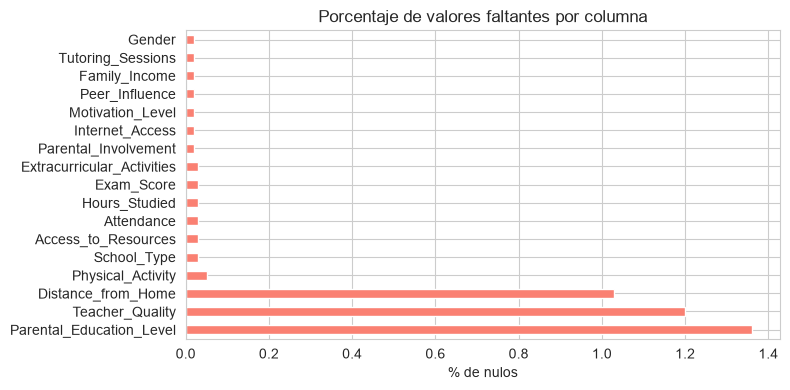

In [134]:
# Visualización rápida de nulos
if missing["nulos"].sum() > 0:
    missing[missing["nulos"] > 0]["porcentaje"].plot(
        kind="barh", figsize=(8, 4), color="salmon"
    )
    plt.title("Porcentaje de valores faltantes por columna")
    plt.xlabel("% de nulos")
    plt.tight_layout()
    plt.show()

### 2.4 Filas duplicadas

Los duplicados exactos suelen indicar errores de captura o concatenación. Si existen, los eliminamos y documentamos el cambio.

In [135]:
duplicados = df.duplicated().sum()
print(f"Filas duplicadas: {duplicados}")

Filas duplicadas: 0


In [136]:
# Si hay duplicados, eliminarlos
if duplicados > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Duplicados eliminados. Nuevo shape: {df.shape}")

## 3️ Limpieza de la variable objetivo

### 3.1 Análisis de `Exam_Score`

Antes de transformar la variable objetivo, exploramos su distribución y verificamos que los valores estén en el rango esperado **(0 – 100)**.

In [137]:
# Distribución original
df["Exam_Score"].describe()

count    6605.000000
mean       67.215291
std         4.217186
min       -65.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

In [138]:
# Ver valores fuera de rango (esperado: 0–100)
print("Mínimo:", df["Exam_Score"].min())
print("Máximo:", df["Exam_Score"].max())
print("Negativos:", (df["Exam_Score"] < 0).sum())
print("Mayores a 100:", (df["Exam_Score"] > 100).sum())

Mínimo: -65.0
Máximo: 101.0
Negativos: 1
Mayores a 100: 1


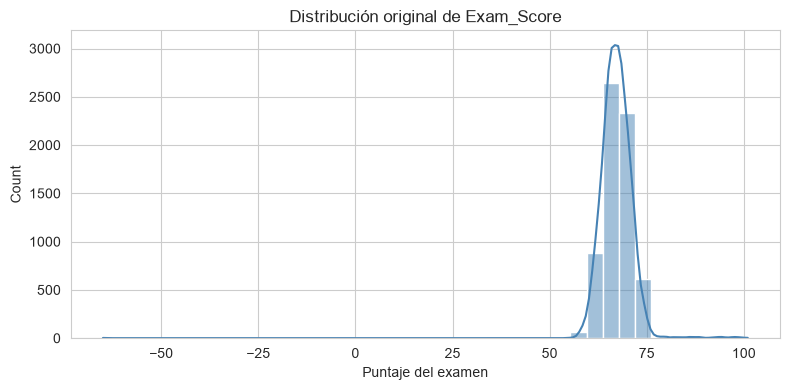

In [139]:
# Distribución de la nota
plt.figure(figsize=(8, 4))
sns.histplot(df["Exam_Score"].dropna(), bins=40, kde=True, color="steelblue")
plt.title("Distribución original de Exam_Score")
plt.xlabel("Puntaje del examen")
plt.tight_layout()
plt.show()

### 3.2 Filtrado de puntajes fuera de rango

**Decisión:** conservar únicamente puntajes entre **0 y 100**. Los valores fuera de este rango son inconsistentes con una escala de calificación estándar y podrían sesgar el modelo.

In [140]:
# 3.2 Filtrado de valores fuera de rango 
n_antes = len(df)

# Target: conservar solo puntajes válidos [0, 100].
# OJO: esto también elimina los 2 nulos de Exam_Score, porque
# las comparaciones con NaN devuelven False. El target NO se imputa.
df = df[(df["Exam_Score"] >= SCORE_MIN) & (df["Exam_Score"] <= SCORE_MAX)].copy()

# Attendance: un porcentaje de asistencia no puede ser negativo.
# Se elimina el valor imposible (-91%) detectado en el diagnóstico.
df = df[(df["Attendance"] >= 0) & (df["Attendance"] <= 100)].copy()

n_despues = len(df)
print(f"Filas eliminadas por valores fuera de rango: {n_antes - n_despues}")
print(f"Exam_Score fuera de [{SCORE_MIN}, {SCORE_MAX}] y sus nulos")
print(f"Attendance fuera de [0, 100]")
print(f"Shape tras el filtro: {df.shape}")

# Verificación explícita
assert df["Exam_Score"].between(SCORE_MIN, SCORE_MAX).all()
assert df["Attendance"].between(0, 100).all()
print("Rangos válidos confirmados")

Filas eliminadas por valores fuera de rango: 7
Exam_Score fuera de [0, 100] y sus nulos
Attendance fuera de [0, 100]
Shape tras el filtro: (6600, 20)
Rangos válidos confirmados


## 4️ Manejo de valores faltantes

### 4.1 Estrategia de imputación

- **Variables numéricas** → imputación con la **mediana** (robusta frente a outliers).
- **Variables categóricas** → imputación con la **moda** (valor más frecuente).

> **Nota:** la propuesta original menciona *KNN imputation* como alternativa. Aquí usamos una estrategia simple y transparente para el EDA; en el modelamiento final se podría comparar con KNN.

> **Orden del pipeline:** los outliers imposibles (`Exam_Score`, `Attendance`) se filtran en la sección 3.2 **antes** de imputar. Así la mediana/moda se calcula sobre datos ya válidos, evitando que valores como `Attendance = -91` contaminen la imputación

In [141]:
# Estrategia:
# - Numéricas: imputar con la mediana (robusta a outliers)
# - Categóricas: imputar con la moda (valor más frecuente)

num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()

print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

Numéricas: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']
Categóricas: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


In [142]:
# Imputación
for col in num_cols:
    if df[col].isna().any():
        mediana = df[col].median()
        df[col] = df[col].fillna(mediana)
        print(f"[num] {col}: imputado con mediana = {mediana}")

for col in cat_cols:
    if df[col].isna().any():
        moda = df[col].mode()[0]
        df[col] = df[col].fillna(moda)
        print(f"[cat] {col}: imputado con moda = {moda}")

[num] Hours_Studied: imputado con mediana = 20.0
[num] Tutoring_Sessions: imputado con mediana = 1.0
[num] Physical_Activity: imputado con mediana = 3.0
[cat] Parental_Involvement: imputado con moda = Medium
[cat] Access_to_Resources: imputado con moda = Medium
[cat] Extracurricular_Activities: imputado con moda = Yes
[cat] Motivation_Level: imputado con moda = Medium
[cat] Internet_Access: imputado con moda = Yes
[cat] Family_Income: imputado con moda = Low
[cat] Teacher_Quality: imputado con moda = Medium
[cat] School_Type: imputado con moda = Public
[cat] Peer_Influence: imputado con moda = Positive
[cat] Parental_Education_Level: imputado con moda = High School
[cat] Distance_from_Home: imputado con moda = Near
[cat] Gender: imputado con moda = Male


In [143]:
# Verificar que ya no queden nulos
print("Nulos restantes:", df.isna().sum().sum())

# Documenta esta decisión en el video de avance: la imputación con mediana/moda
# es una decisión inicial; en el modelamiento final se podría comparar con KNN imputation.



Nulos restantes: 0


### 4.2 Limpieza de variables categóricas

Eliminamos espacios al inicio/final y verificamos que no existan **inconsistencias** (mayúsculas mezcladas, sinónimos, etc.).

In [144]:
# Revisar valores únicos en categóricas para detectar inconsistencias
for col in cat_cols:
    print(f"\n {col} ")
    print(df[col].value_counts(dropna=False))


 Parental_Involvement 
Parental_Involvement
Medium    3359
High      1907
Low       1334
Name: count, dtype: int64

 Access_to_Resources 
Access_to_Resources
Medium    3314
High      1974
Low       1312
Name: count, dtype: int64

 Extracurricular_Activities 
Extracurricular_Activities
Yes    3932
No     2668
Name: count, dtype: int64

 Motivation_Level 
Motivation_Level
Medium    3350
Low       1932
High      1318
Name: count, dtype: int64

 Internet_Access 
Internet_Access
Yes    6102
No      498
Name: count, dtype: int64

 Family_Income 
Family_Income
Low       2671
Medium    2661
High      1268
Name: count, dtype: int64

 Teacher_Quality 
Teacher_Quality
Medium    4000
High      1945
Low        655
Name: count, dtype: int64

 School_Type 
School_Type
Public     4593
Private    2007
Name: count, dtype: int64

 Peer_Influence 
Peer_Influence
Positive    2636
Neutral     2588
Negative    1376
Name: count, dtype: int64

 Learning_Disabilities 
Learning_Disabilities
No     5905
Yes     

In [145]:
# Limpieza básica: eliminar espacios y estandarizar capitalización
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip()

### 5 Feature engineering: variable Approved

### 5.1 Creación de la variable binaria

Convertimos `Exam_Score` en una **variable objetivo binaria**:

- `Approved = 1` → `Exam_Score >= 65`
- `Approved = 0` → en caso contrario

**¿Por qué 65 y no 59.5?** El umbral original producía 98.97% aprobados / 1.03% reprobados, un desbalance inviable para clasificación. El valor 65 corresponde al percentil 25 de `Exam_Score`, genera clases ~75/25 y alinea el análisis con la pregunta del proyecto

In [146]:
# 5.1 Variable binaria: aprobado (1) / reprobado (0) 
# Se usa UMBRAL_APROBACION definido en la configuración global (sección 1.1).
# Justificación del umbral 65 (percentil 25): el umbral original 59.5
# producía un desbalance ~99:1 inviable para clasificación. Con 65 se
# obtiene una distribución tratable (~75/25) y se enfoca en detectar a
# los estudiantes por debajo del cuartil inferior de rendimiento.
df["Approved"] = (df["Exam_Score"] >= UMBRAL_APROBACION).astype(int)

conteo = df["Approved"].value_counts().sort_index()
print(conteo)
print(f"\nTasa de aprobación (umbral={UMBRAL_APROBACION}): {df['Approved'].mean():.2%}")

# Diagnóstico de balance
prop_min = df["Approved"].value_counts(normalize=True).min()
print(f"Clase minoritaria: {prop_min:.2%}")
if prop_min < 0.20:
    print("Desbalance relevante (>80/20). Considerar class_weight o SMOTE en modelamiento.")
else:
    print("Balance aceptable para clasificación.")

Approved
0    1451
1    5149
Name: count, dtype: int64

Tasa de aprobación (umbral=65): 78.02%
Clase minoritaria: 21.98%
Balance aceptable para clasificación.


C:\Users\Estudiante\AppData\Local\Temp\ipykernel_11212\563360205.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Approved", data=df, palette=["#e74c3c", "#2ecc71"])


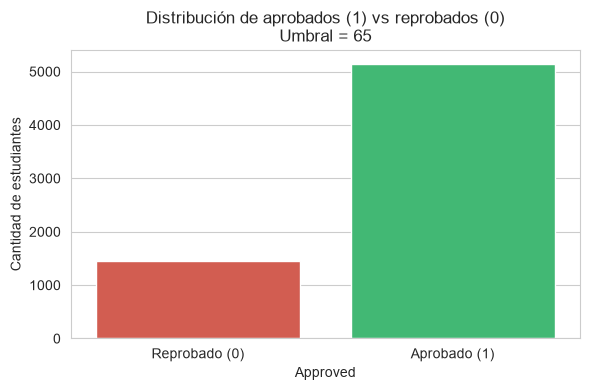

In [147]:
# Visualización
plt.figure(figsize=(6, 4))
sns.countplot(x="Approved", data=df, palette=["#e74c3c", "#2ecc71"])
plt.title(f"Distribución de aprobados (1) vs reprobados (0)\nUmbral = {UMBRAL_APROBACION}")
plt.xlabel("Approved")
plt.ylabel("Cantidad de estudiantes")
plt.xticks([0, 1], ["Reprobado (0)", "Aprobado (1)"])
plt.tight_layout()
plt.show()

### 5.2 Verificación y casteo de tipos

Aseguramos que cada columna tenga el **tipo correcto** antes de exportar:

- `Exam_Score` → `float`
- `Approved` → `int`
- Categóricas → `category` (más eficiente en memoria)

In [148]:
df.dtypes

Hours_Studied                 float64
Attendance                    float64
Parental_Involvement           object
Access_to_Resources            object
Extracurricular_Activities     object
Sleep_Hours                     int64
Previous_Scores                 int64
Motivation_Level               object
Internet_Access                object
Tutoring_Sessions             float64
Family_Income                  object
Teacher_Quality                object
School_Type                    object
Peer_Influence                 object
Physical_Activity             float64
Learning_Disabilities          object
Parental_Education_Level       object
Distance_from_Home             object
Gender                         object
Exam_Score                    float64
Approved                        int64
dtype: object

In [149]:
# Forzar tipos correctos
df["Exam_Score"] = df["Exam_Score"].astype(float)
df["Approved"]   = df["Approved"].astype(int)

# Convertir categóricas a tipo category (más eficiente)
for col in cat_cols:
    df[col] = df[col].astype("category")

df.dtypes

Hours_Studied                  float64
Attendance                     float64
Parental_Involvement          category
Access_to_Resources           category
Extracurricular_Activities    category
Sleep_Hours                      int64
Previous_Scores                  int64
Motivation_Level              category
Internet_Access               category
Tutoring_Sessions              float64
Family_Income                 category
Teacher_Quality               category
School_Type                   category
Peer_Influence                category
Physical_Activity              float64
Learning_Disabilities         category
Parental_Education_Level      category
Distance_from_Home            category
Gender                        category
Exam_Score                     float64
Approved                         int64
dtype: object

## 6️ Exportación del dataset limpio

Guardamos el resultado en `data/processed/` para que los siguientes notebooks (EDA, modelamiento) partan de un dataset **consistente y reproducible**.

In [ ]:
# Guardar el dataset procesado
df.to_csv(PROCESSED_PATH, index=False)
print(f" Dataset limpio guardado en: {PROCESSED_PATH}")
print(f"Shape final: {df.shape}")

# Verificación post-export (reproducibilidad)
df_check = pd.read_csv(PROCESSED_PATH)
assert df_check.shape == df.shape, "El CSV no coincide en forma"
assert df_check.isna().sum().sum() == 0, "Quedan nulos en el CSV"
assert "Approved" in df_check.columns, "Falta la columna Approved"
assert df_check["Exam_Score"].between(0, 100).all(), "Exam_Score fuera de rango en el CSV"

print(" Verificación post-export OK")

 Dataset limpio guardado en: ..\data\processed\student_performance_clean.csv
Shape final: (6600, 21)
 Verificación post-export OK


##  Resumen del proceso de limpieza

Tabla-resumen con los cambios aplicados, útil para el **video de avance**.

In [151]:
resumen = {
    "Filas iniciales": 6607,
    "Filas finales": len(df),
    "Columnas finales": df.shape[1],
    "Nulos restantes": int(df.isna().sum().sum()),
    "Umbral de aprobación": UMBRAL_APROBACION,
    "Tasa de aprobación": f"{df['Approved'].mean():.2%}",
    "Clase minoritaria": f"{df['Approved'].value_counts(normalize=True).min():.2%}",
}
for k, v in resumen.items():
    print(f"{k}: {v}")

Filas iniciales: 6607
Filas finales: 6600
Columnas finales: 21
Nulos restantes: 0
Umbral de aprobación: 65
Tasa de aprobación: 78.02%
Clase minoritaria: 21.98%
